In [1]:
import geopandas as gpd

path = r"D:\Mahadev\NORDHAVEN_GEOSPATIAL_LAB\04_GIS_Database\Nordhaven_Infrastructure.gpkg"
lines = gpd.read_file(path, layer="infrastructure_lines")
lines.head()

,feature_id,infrastructure_type,material,condition,source_ref,review_status,remarks,geometry
0,1,curb,concrete,good,manual_digitisation_01,pending,Sample curb feature,"LINESTRING (473036.429 5929296.463, 473074.182..."
1,2,curb,concrete,good,manual_digitisation_02,pending,Sample curb segment 02,"LINESTRING (473030.891 5929313.341, 473041.753..."
2,3,drainage_channel,concrete,good,manual_digitisation_03,pending,Sample drainage alignment,"LINESTRING (473030.691 5929312.775, 473041.553..."
3,4,curb,concrete,good,manual_digitisation_04,pending,Sample curb segment 03,"LINESTRING (473129.851 5929286.902, 473142.126..."
4,5,drainage_channel,concrete,good,manual_digitisation_05,pending,Sample drainage alignment 02,"LINESTRING (473130.421 5929287.087, 473142.696..."


EPSG:25832


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

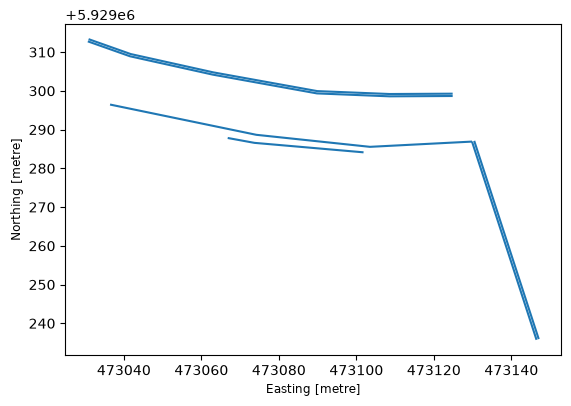

In [2]:
print(lines.crs)
lines.plot()

In [3]:
print("Rows:", len(lines))
print("Columns:", list(lines.columns))
lines["infrastructure_type"].value_counts()

Rows: 6
Columns: ['feature_id', 'infrastructure_type', 'material', 'condition', 'source_ref', 'review_status', 'remarks', 'geometry']


infrastructure_type
curb                3
drainage_channel    2
crash_barrier       1
Name: count, dtype: int64

In [4]:
lines["length_m"] = lines.length.round(2)
lines[["feature_id", "infrastructure_type", "length_m"]]

,feature_id,infrastructure_type,length_m
0,1,curb,94.42
1,2,curb,95.59
2,3,drainage_channel,95.80
3,4,curb,53.80
4,5,drainage_channel,53.80
5,6,crash_barrier,35.28


In [5]:
lines.groupby("infrastructure_type")["length_m"].agg(["count", "sum"]).round(1)

,count,sum
infrastructure_type,,
crash_barrier,1,35.3
curb,3,243.8
drainage_channel,2,149.6


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

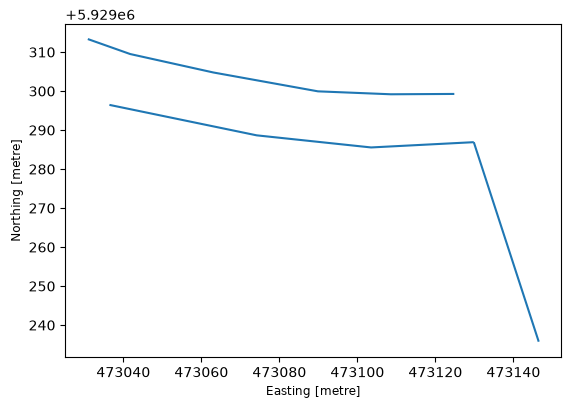

In [6]:
curbs = lines[lines["infrastructure_type"] == "curb"]
curbs.plot()

In [7]:
lines.to_crs(4326).length.head(2)

C:\Users\RoterLP\AppData\Local\Temp\ipykernel_16984\3691632548.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  lines.to_crs(4326).length.head(2)


0    0.001415
1    0.001426
dtype: float64

In [8]:
allowed = {
    "infrastructure_type": ["crash_barrier", "curb", "drainage_channel"],
    "material": ["concrete", "metal"],
    "condition": ["good"],
    "review_status": ["pending"],
}


def run_checks(gdf):
    results = []

    # 1. Missing or empty geometry
    bad = gdf[gdf.geometry.isna() | gdf.geometry.is_empty]
    results.append(("Missing or empty geometry", len(bad)))

    # 2. Invalid geometry
    bad = gdf[~gdf.geometry.is_valid]
    results.append(("Invalid geometry", len(bad)))

    # 3. Very short lines (under 1 m)
    bad = gdf[gdf.length < 1]
    results.append(("Lines shorter than 1 m", len(bad)))

    # 4. Duplicate feature_id
    bad = gdf[gdf["feature_id"].duplicated(keep=False)]
    results.append(("Duplicate feature_id", len(bad)))

    # 5. Empty important columns
    for col in ["feature_id", "infrastructure_type", "material"]:
        bad = gdf[gdf[col].isna()]
        results.append((f"Empty {col}", len(bad)))

    # 6. Values outside the allowed list
    for col, ok_values in allowed.items():
        bad = gdf[~gdf[col].isin(ok_values)]
        results.append((f"{col} not in allowed list", len(bad)))

    # Report
    for name, count in results:
        status = "PASS" if count == 0 else "FAIL"
        print(f"{status}  {name}: {count}")

In [9]:
run_checks(lines)

PASS  Missing or empty geometry: 0
PASS  Invalid geometry: 0
PASS  Lines shorter than 1 m: 0
PASS  Duplicate feature_id: 0
PASS  Empty feature_id: 0
PASS  Empty infrastructure_type: 0
PASS  Empty material: 0
PASS  infrastructure_type not in allowed list: 0
PASS  material not in allowed list: 0
PASS  condition not in allowed list: 0
PASS  review_status not in allowed list: 0


In [10]:
test = lines.copy()
test.loc[0, "material"] = "Concrete"   # wrong capital letter
test.loc[1, "feature_id"] = 3          # duplicate ID
test.loc[2, "condition"] = None        # empty value
run_checks(test)

PASS  Missing or empty geometry: 0
PASS  Invalid geometry: 0
PASS  Lines shorter than 1 m: 0
FAIL  Duplicate feature_id: 2
PASS  Empty feature_id: 0
PASS  Empty infrastructure_type: 0
PASS  Empty material: 0
PASS  infrastructure_type not in allowed list: 0
FAIL  material not in allowed list: 1
FAIL  condition not in allowed list: 1
PASS  review_status not in allowed list: 0


In [11]:
summary = lines.groupby("infrastructure_type")["length_m"].agg(["count", "sum"]).round(1)
summary.to_csv(r"D:\Mahadev\GIS_Sprint\length_summary.csv")
summary

,count,sum
infrastructure_type,,
crash_barrier,1,35.3
curb,3,243.8
drainage_channel,2,149.6


In [12]:
import pandas as pd
pd.read_csv(r"D:\Mahadev\GIS_Sprint\length_summary.csv")

,infrastructure_type,count,sum
0,crash_barrier,1,35.3
1,curb,3,243.8
2,drainage_channel,2,149.6


In [13]:
curbs.to_crs(4326).to_file(r"D:\Mahadev\GIS_Sprint\curbs.geojson", driver="GeoJSON")